# 02 · Regresión logística: clase de utilidad de una parcela

**Responsable:** Fabiana Leonardo (@fabileoruf). **Historia:** [#38](https://github.com/IA-P1-BCN/g3-Clasificacion-Multiclase/issues/38); subtareas #52, #53 y #54.

Predecimos `Utility` en las cinco clases `none`, `low`, `average`, `good` y `best`.
El objetivo es superar el Dummy con un pipeline reproducible y un gap de F1 macro inferior a 5 puntos.
La regresión logística calcula probabilidades multiclase; no interpreta la distancia entre clases como una regresión numérica.

Se usan los CSV compartidos y la biblioteca obligatoria `comun.py`, según [los acuerdos](docs/acuerdos.md).
No se vuelve a hacer el split ni la limpieza del EDA. El conjunto reservado para la evaluación final se mantiene sin leer.

**Ejecución:** abrir este notebook desde la raíz del repositorio, seleccionar el entorno `.venv` con las dependencias de `requirements.txt` y ejecutar todas las celdas, en orden.


## 1. Entorno y funciones comunes

Las decisiones específicas del algoritmo están aquí; carga, baseline, CV, regla `none`, evaluación y exportación se importan de `comun.py`.


In [1]:
import json
import subprocess
import sys
from functools import partial
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from comun import (
    CLASES, GAP_MAXIMO, NUMERICAS, RAIZ, SEMILLA,
    baseline_dummy, cargar_datos, conclusion_modelo, cv_comun,
    elegir_sin_sobreajuste, errores_frecuentes, evaluar_val,
    f1_por_fold, guardar_modelo, mostrar_evaluacion,
    separar_xy, sin_medidas,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

NOMBRE_RL = "02_regresion_logistica"
print("Python:", sys.version.split()[0])
print({paquete: version(paquete) for paquete in ["numpy", "pandas", "scikit-learn", "joblib"]})


Python: 3.14.7
{'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'joblib': '1.6.0'}


## 2. Datos compartidos

La limpieza de `01_eda` ya excluye las parcelas sin medidas de train. Validación las conserva.
`Abbrev` se conserva también para la comprobación de generalización a sitios nuevos.
Las distribuciones que se muestran aquí corresponden únicamente a entrenamiento.


In [2]:
train_rl, val_rl = cargar_datos()
X_train_rl, y_train_rl = separar_xy(train_rl)
X_val_rl, y_val_rl = separar_xy(val_rl)

assert set(y_train_rl.unique()) == set(CLASES)
assert not sin_medidas(X_train_rl).any(), "Revisar los CSV comunes: train contiene parcelas sin medidas."
print(f"Train: {len(train_rl)} parcelas. Validación: {len(val_rl)} parcelas.")
print(f"Validación sin medidas: {sin_medidas(X_val_rl).sum()} (se aplica la regla none).")
display(y_train_rl.value_counts().reindex(CLASES).rename_axis("clase de utilidad").to_frame("parcelas de entrenamiento"))


Train: 469 parcelas. Validación: 110 parcelas.
Validación sin medidas: 15 (se aplica la regla none).


,parcelas de entrenamiento
clase de utilidad,
none,80
low,75
average,91
good,150
best,73


## 3. Preprocesado y decisiones

| Decisión | Por qué |
|---|---|
| Usar las 8 medidas numéricas de `NUMERICAS` | Son mediciones de campo; deben estar disponibles cuando se prediga. |
| Imputar con la mediana y aplicar `StandardScaler` | Resolver los ausentes de supervivencia y diámetro; evitar que las unidades dominen la regularización. |
| Codificar `Abbrev` y `Sp` con one-hot | Son categorías sin orden numérico. Las categorías desconocidas se toleran; los valores raros se agrupan si aparecen menos de 3 veces en el fold. |
| Excluir `Rep` y `PMCno` mediante `remainder="drop"` | Son identificadores del diseño del ensayo y de procedencia; no se supone una relación ordinal entre sus números y la utilidad. |
| Conservar `DBH`/`Ht` y las tres medidas de forma, con regularización L2 | El EDA detectó correlaciones. L2 limita los coeficientes sin eliminar arbitrariamente una medida; dificulta atribuir importancia individual a variables correlacionadas. |
| Comparar `class_weight=None` y `"balanced"` | Atender al desbalance moderado sin crear parcelas sintéticas. La elección se hace solo con CV sobre train. |

Todo el preprocesado está dentro del `Pipeline`: cada fold ajusta sus propias medianas, escalas y categorías.
Las columnas descartadas siguen en el DataFrame de entrada para que la biblioteca común pueda comprobar los sitios y las medidas.

Referencias de la API: [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) y [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).


In [3]:
numericas_rl = list(NUMERICAS)
categoricas_rl = ["Abbrev", "Sp"]

preprocesado_rl = ColumnTransformer(
    transformers=[
        ("numericas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), numericas_rl),
        ("categoricas", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", min_frequency=3)),
        ]), categoricas_rl),
    ],
    remainder="drop",
)

pipeline_rl = Pipeline([
    ("preprocesado", preprocesado_rl),
    ("logistica", LogisticRegression(
        solver="lbfgs", l1_ratio=0.0, max_iter=5000, random_state=SEMILLA,
    )),
])


## 4. Baseline común

El Dummy predice la clase más frecuente de entrenamiento. La regla `none` se aplica también al baseline, para comparar en las mismas condiciones.


In [4]:
dummy_rl = baseline_dummy(X_train_rl, y_train_rl, X_val_rl, y_val_rl)


El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.244,0.427
solo con medidas,0.101,0.337


## 5. Selección de hiperparámetros, solo con entrenamiento

La rejilla se fija antes de evaluar el modelo en validación. Un `C` pequeño implica mayor regularización.
Se usa `elegir_sin_sobreajuste`: mayor F1 macro en CV entre candidatos con gap train–CV inferior a 5 puntos; en empate se favorece menor `C`.
Si ninguno cumple, la biblioteca elige el menor gap y lo avisa. No se reajusta la rejilla mirando validación.


In [5]:
rejilla_rl = {
    "logistica__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0],
    "logistica__class_weight": [None, "balanced"],
}
busqueda_rl = GridSearchCV(
    pipeline_rl,
    param_grid=rejilla_rl,
    scoring="f1_macro",
    cv=cv_comun(),
    return_train_score=True,
    refit=partial(elegir_sin_sobreajuste, desempate=[("param_logistica__C", True)]),
    n_jobs=-1,
    error_score="raise",
)
busqueda_rl.fit(X_train_rl, y_train_rl)
modelo_rl = busqueda_rl.best_estimator_

tabla_busqueda_rl = pd.DataFrame(busqueda_rl.cv_results_)
tabla_busqueda_rl["gap_cv_puntos"] = 100 * (tabla_busqueda_rl["mean_train_score"] - tabla_busqueda_rl["mean_test_score"])
tabla_busqueda_rl["elegido"] = tabla_busqueda_rl.index == busqueda_rl.best_index_
display(tabla_busqueda_rl[[
    "param_logistica__C", "param_logistica__class_weight",
    "mean_train_score", "mean_test_score", "std_test_score", "gap_cv_puntos", "elegido",
]].sort_values("mean_test_score", ascending=False).round(4))
print("Hiperparámetros elegidos solo con train:", busqueda_rl.best_params_)
print("Iteraciones hasta converger:", modelo_rl.named_steps["logistica"].n_iter_)


,param_logistica__C,param_logistica__class_weight,mean_train_score,mean_test_score,std_test_score,gap_cv_puntos,elegido
17,10.000,balanced,0.7948,0.5835,0.0515,21.1302,False
16,10.000,NaN,0.8061,0.5835,0.0766,22.2551,False
14,3.000,NaN,0.7771,0.5799,0.0792,19.7183,False
18,30.000,NaN,0.8131,0.5770,0.0731,23.6036,False
12,1.000,NaN,0.7454,0.5766,0.0605,16.8741,False
13,1.000,balanced,0.7421,0.5735,0.0402,16.8595,False
11,0.300,balanced,0.7089,0.5692,0.0449,13.9666,False
19,30.000,balanced,0.8085,0.5683,0.0605,24.0191,False
10,0.300,NaN,0.7016,0.5674,0.0823,13.4181,False
15,3.000,balanced,0.7687,0.5632,0.0590,20.5492,False


Hiperparámetros elegidos solo con train: {'logistica__C': 0.003, 'logistica__class_weight': 'balanced'}
Iteraciones hasta converger: [10]


## 6. Validación cruzada común y por sitio — #52

Se presentan los cinco folds, la media y la desviación con ambos esquemas comunes.
La comprobación por sitio utiliza `Abbrev` como grupo y no se utiliza para retocar el modelo.
La CV común comparte los folds usados para elegir hiperparámetros: su resultado es descriptivo tras selección, no una estimación independiente de ella.


In [6]:
cv_rl = f1_por_fold(modelo_rl, X_train_rl, y_train_rl)
print(f"Diferencia CV común − CV por sitio: {100 * (cv_rl['f1'] - cv_rl['f1_sitio']):.2f} puntos.")


,StratifiedKFold,por sitio (StratifiedGroupKFold)
fold,,
1,0.408,0.376
2,0.439,0.407
3,0.470,0.369
4,0.419,0.381
5,0.436,0.450


StratifiedKFold: F1 macro = 0.434 ± 0.021 | gap 3.4 puntos ✅ correcto
Por sitio:       F1 macro = 0.397 ± 0.030 | gap 7.6 puntos
Diferencia CV común − CV por sitio: 3.75 puntos.


## 7. Evaluación en validación y overfitting — #53

`evaluar_val` usa `predecir_con_regla`: las parcelas sin medidas reciben `none` **sin entrar al modelo**.
Se muestran accuracy, precision/recall/F1 por clase y matrices de confusión, tanto sobre toda la validación como solo sobre parcelas con medidas.

El gap acordado es `(F1 train − F1 validación con medidas) × 100`, **con signo**.
El resultado sobre toda la validación incluye el acierto de la regla y se usa para comparar los modelos del equipo.


### Lectura de la ejecución entregada

El gap observado es **6,52 puntos**: F1 de train **0,4943** frente a **0,4291** en las 95 parcelas de validación con medidas. **No cumple el límite de 5 puntos**. El F1 de toda la validación es **0,4677**, con accuracy **0,5091**; las 15 parcelas sin medidas se resuelven por la regla.

La selección por CV había dado un gap de 3,41 puntos, pero esa condición no garantiza el mismo resultado en un conjunto diferente. La CV compara modelos ajustados en cuatro folds y el pipeline exportado se ajusta en las 469 parcelas de train; además, validación con medidas solo tiene 95 parcelas. Esas diferencias pueden contribuir al gap, pero esta ejecución no permite aislar una causa única.

El `C=0,003` elegido impone regularización fuerte y el rendimiento absoluto es limitado, especialmente en las clases intermedias. Un gap pequeño en CV no basta para afirmar que un modelo es bueno. Se conserva la elección hecha con train y se documenta el incumplimiento, tal como admite el criterio de #38, sin usar validación para seleccionar otra configuración.


1. MÉTRICAS EN VALIDACIÓN


,F1 macro,nivel F1,supera Dummy (puntos),nivel baseline,accuracy,accuracy balanceada,precision macro,recall macro,F1 ponderado
toda la validación,0.468,⚠️ flojo,22.406,⚠️ supera poco,0.509,0.517,0.511,0.517,0.474
solo con medidas,0.429,⚠️ flojo,32.831,✅ supera claramente,0.432,0.498,0.466,0.498,0.401


2. OVERFITTING: F1 train 0.494 - F1 validación con medidas 0.429 = 6.5 puntos → ❌ ligero sobreajuste
3. MÉTRICAS POR CLASE


toda la validación                      solo con medidas                     
                 precision recall    f1 soporte        precision recall    f1 soporte
none                  0.68   0.93  0.78    27.0             0.45   0.83  0.59    12.0
low                   0.53   0.56  0.55    16.0             0.53   0.56  0.55    16.0
average               0.50   0.16  0.24    19.0             0.50   0.16  0.24    19.0
good                  0.53   0.25  0.34    32.0             0.53   0.25  0.34    32.0
best                  0.31   0.69  0.43    16.0             0.31   0.69  0.43    16.0

4. MATRICES DE CONFUSIÓN


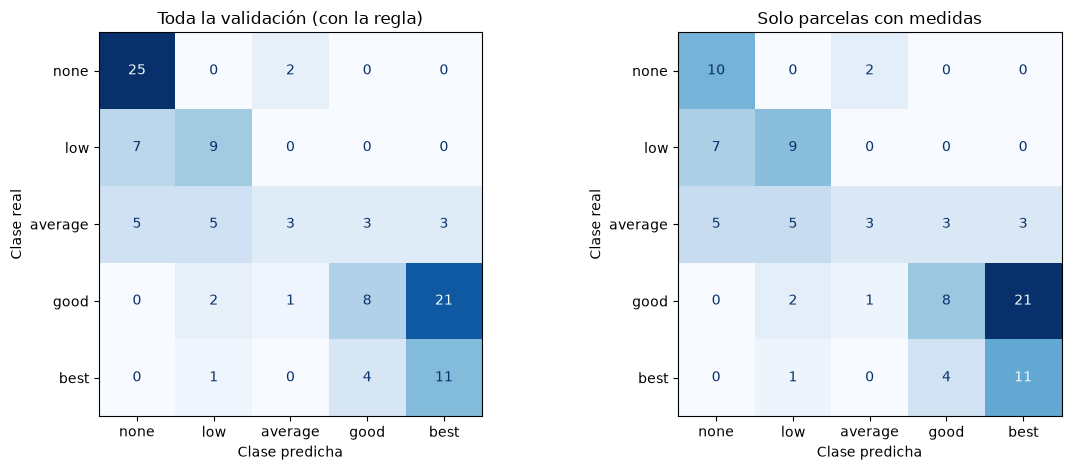

No cumple el límite de sobreajuste: se documenta el resultado y no se ajustan hiperparámetros usando esta validación. No es candidato al modelo ganador con la regla actual.


In [7]:
evaluacion_rl = evaluar_val(modelo_rl, X_train_rl, y_train_rl, X_val_rl, y_val_rl, dummy_rl)
mostrar_evaluacion(evaluacion_rl)

if evaluacion_rl["gap"] < -GAP_MAXIMO:
    print("La validación supera al entrenamiento por más de 5 puntos. Cumple la regla de sobreajuste, pero este split pequeño puede ser más favorable; no demuestra generalización perfecta.")
elif not evaluacion_rl["cumple_gap"]:
    print("No cumple el límite de sobreajuste: se documenta el resultado y no se ajustan hiperparámetros usando esta validación. No es candidato al modelo ganador con la regla actual.")
else:
    print("Cumple el límite de sobreajuste acordado. La comprobación por sitio y los errores siguen siendo necesarios para valorar sus límites.")


## 8. Interpretación por coeficientes — #54

La importancia nativa se resume como la media del valor absoluto de los coeficientes de las cinco clases, por variable transformada.
Las numéricas están estandarizadas; las indicadoras one-hot están en escala 0/1. Es una lectura del modelo, no una medida causal ni una comparación exacta entre tipos de variable.
Las variables correlacionadas pueden repartirse los coeficientes. La tabla por clase conserva el signo y permite ver qué asociaciones favorecen cada clase.


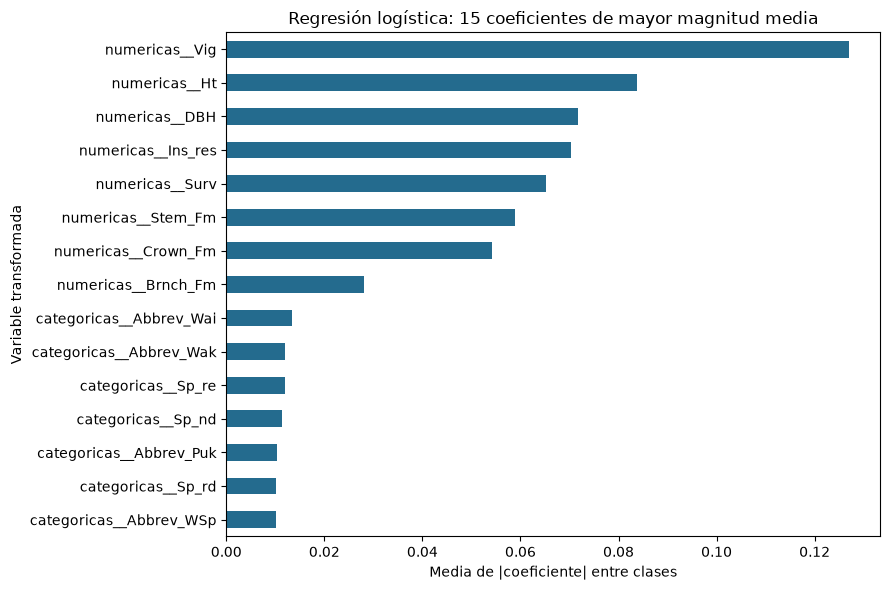

,none,low,average,good,best
numericas__Vig,-0.220,-0.097,0.017,0.109,0.191
numericas__Ht,-0.097,-0.099,-0.014,0.084,0.125
numericas__DBH,-0.104,-0.067,-0.008,0.080,0.099
numericas__Ins_res,-0.104,-0.072,0.015,0.060,0.100
numericas__Surv,-0.147,0.037,-0.016,0.054,0.072
numericas__Stem_Fm,-0.087,-0.055,-0.005,0.037,0.111
numericas__Crown_Fm,-0.099,-0.036,0.006,0.030,0.099
numericas__Brnch_Fm,-0.050,0.014,-0.001,-0.019,0.056
categoricas__Abbrev_Wai,0.006,0.007,-0.019,-0.015,0.021
categoricas__Abbrev_Wak,0.030,-0.007,-0.012,-0.011,-0.000


In [8]:
nombres_variables_rl = modelo_rl.named_steps["preprocesado"].get_feature_names_out()
coeficientes_rl = pd.DataFrame(
    modelo_rl.named_steps["logistica"].coef_.T,
    index=nombres_variables_rl,
    columns=modelo_rl.named_steps["logistica"].classes_,
).reindex(columns=CLASES)
importancia_rl = coeficientes_rl.abs().mean(axis=1).sort_values(ascending=False)
principales_rl = importancia_rl.head(15)

fig_rl, ax_rl = plt.subplots(figsize=(9, 6))
principales_rl.sort_values().plot.barh(ax=ax_rl, color="#246b8e")
ax_rl.set(title="Regresión logística: 15 coeficientes de mayor magnitud media", xlabel="Media de |coeficiente| entre clases", ylabel="Variable transformada")
fig_rl.tight_layout()
plt.show()
display(coeficientes_rl.loc[principales_rl.index].round(3))


## 9. Análisis de errores — #54

Se ordenan las confusiones reales y se inspeccionan parcelas mal clasificadas junto con su vigor y otras medidas.
La escala de utilidad es ordenada, aunque la regresión logística multinomial no impone ese orden.
Una confusión entre clases vecinas puede ser compatible con medidas de campo parecidas; una de dos o más niveles requiere especial atención.
Estas explicaciones son hipótesis, no causas demostradas por el modelo.


**Lectura de los errores observados:** 54 de 110 parcelas se clasifican mal: 41 errores son entre clases vecinas y 13 saltan dos o más niveles. La confusión principal es `good → best` (21 parcelas); el recall de `good` es 0,25 y el de `average` solo 0,158. El modelo separa mejor los extremos que las clases intermedias.

Los coeficientes muestran que un vigor alto favorece tanto `good` como `best`, con mayor coeficiente para `best`. Esto es compatible con la confusión principal, aunque también intervienen las demás medidas y los interceptos. El peso equilibrado de clases y la regularización fuerte son posibles factores; no se ha hecho una comparación causal que lo demuestre. También aparecen `low → none` (7 parcelas) y `average → none` (5), que requieren revisar las medidas y el contexto del sitio.

El F1 cae de 0,434 en CV común a 0,397 por sitio. La diferencia de 3,75 puntos confirma que ambas evaluaciones cuentan historias distintas; no se puede trasladar el resultado del split común sin más a sitios nuevos. `Vig` es el coeficiente de mayor magnitud media, seguido por altura y diámetro; la interpretación no demuestra causalidad.


In [9]:
errores_rl = errores_frecuentes(evaluacion_rl["y"], evaluacion_rl["pred"])
display(errores_rl)

parcelas_error_rl = X_val_rl.assign(real=y_val_rl, predicha=evaluacion_rl["pred"])
parcelas_error_rl = parcelas_error_rl.loc[parcelas_error_rl["real"] != parcelas_error_rl["predicha"]]
display(parcelas_error_rl[["Abbrev", "Sp", "Vig", "Surv", "Ins_res", "real", "predicha"]].head(12))

for error_rl in errores_rl.head(3).itertuples(index=False):
    print(f"{error_rl.real} → {error_rl.predicha}: {error_rl.parcelas} parcelas; distancia de {error_rl.distancia} niveles.")
if cv_rl["f1_sitio"] < cv_rl["f1"]:
    print("La caída al separar sitios es compatible con dependencia del contexto del sitio. El rendimiento en sitios nuevos debe comunicarse con esta limitación (ADR-0002).")
print("Vig y el resto de medidas deben estar disponibles en la parcela al predecir. Si faltan todas, responde la regla; no se interpreta como éxito de la regresión logística.")


Errores: 54 de 110. Entre clases vecinas: 41; a 2 o más clases de distancia: 13.


,real,predicha,parcelas,distancia
0,good,best,21,1
1,low,none,7,1
2,average,none,5,2
3,average,low,5,1
4,best,good,4,1
5,average,best,3,2
6,average,good,3,1
7,good,low,2,2
8,none,average,2,2
9,best,low,1,3


,Abbrev,Sp,Vig,Surv,Ins_res,real,predicha
3,K81,si,3.0,25.0,3.0,average,none
4,K81,re,4.0,63.0,3.5,good,best
5,K81,br,3.0,88.0,2.0,best,low
7,Cra,ov,3.0,100.0,1.8,average,low
9,Puk,nd,2.5,75.0,2.0,average,low
13,Puk,ov,3.0,75.0,2.0,average,low
16,Paw,co,3.6,30.0,3.8,good,best
21,K81a,re,2.5,7.0,3.0,low,none
22,Lon,co,3.5,100.0,3.0,good,best
23,Paw,nd,3.0,20.0,4.0,average,best


good → best: 21 parcelas; distancia de 1 niveles.
low → none: 7 parcelas; distancia de 1 niveles.
average → none: 5 parcelas; distancia de 2 niveles.
La caída al separar sitios es compatible con dependencia del contexto del sitio. El rendimiento en sitios nuevos debe comunicarse con esta limitación (ADR-0002).
Vig y el resto de medidas deben estar disponibles en la parcela al predecir. Si faltan todas, responde la regla; no se interpreta como éxito de la regresión logística.


## 10. Exportación y recarga en una sesión nueva — #54

Se guarda el pipeline completo con la función común. Además de su comprobación de recarga, se abre un proceso Python independiente y se verifica que produce exactamente las mismas predicciones en validación.
La regla de parcelas sin medidas vive en `comun.py`: la app debe llamar a `predecir_con_regla`, no al pipeline directamente sobre esas parcelas.


In [10]:
ruta_modelo_rl = guardar_modelo(modelo_rl, NOMBRE_RL, X_val_rl)

codigo_recarga_rl = """
import json
import joblib
import pandas as pd
from comun import DATOS, MODELOS, predecir_con_regla, separar_xy

modelo = joblib.load(MODELOS / "02_regresion_logistica.joblib")
validacion = pd.read_csv(DATOS / "val.csv", encoding="utf-8")
X, _ = separar_xy(validacion)
predicciones = predecir_con_regla(modelo, X)
print(json.dumps(predicciones.tolist()))
"""
sesion_nueva_rl = subprocess.run(
    [sys.executable, "-c", codigo_recarga_rl],
    cwd=RAIZ, check=True, capture_output=True, text=True, encoding="utf-8",
)
predicciones_recargadas_rl = json.loads(sesion_nueva_rl.stdout)
assert predicciones_recargadas_rl == evaluacion_rl["pred"].tolist()
print(f"Sesión Python nueva: {len(predicciones_recargadas_rl)} predicciones idénticas.")


Guardado: models/02_regresion_logistica.joblib (7.3 KB). ¿Al recargarlo predice igual? ✅
Sesión Python nueva: 110 predicciones idénticas.


## 11. Conclusión y entrega común

La tabla de requisitos y el JSON se generan con `conclusion_modelo`. Se entregan este notebook ejecutado, el pipeline y `resultados/02_regresion_logistica.json` para la comparación de `06_conclusiones`.

**Requisitos cualitativos:** preprocesado dentro del pipeline (§3); importancia nativa con gráfico y coeficientes por clase (§8); confusiones y parcelas mal clasificadas (§9); recarga en proceso independiente (§10).
El equipo elegirá el modelo ganador entre sus cuatro algoritmos. Este notebook no realiza la evaluación final del equipo.


**Resultado:** el modelo supera al Dummy (F1 global 0,468 frente a 0,244) y se entrega para comparación, pero **no es candidato al modelo ganador**, porque su gap de 6,52 puntos incumple el umbral. El JSON deja `cumple_gap=false`; no se presenta el requisito R2 como conseguido.

El pipeline convergió sin avisos y su recarga en otro proceso reprodujo las 110 predicciones. Una siguiente iteración metodológica debería estudiar la selección en CV y la separación de clases intermedias, manteniendo el conjunto final reservado y dejando constancia de que esta validación ya se ha observado.


In [11]:
ruta_resultados_rl = conclusion_modelo(
    NOMBRE_RL, cv_rl, evaluacion_rl, dummy_rl, busqueda_rl.best_params_,
)
print(f"F1 macro en toda la validación: {evaluacion_rl['filas']['toda la validación']['F1 macro']:.3f}")
print(f"F1 macro solo con medidas: {evaluacion_rl['filas']['solo con medidas']['F1 macro']:.3f}")
print(f"Gap de sobreajuste: {evaluacion_rl['gap']:.2f} puntos; cumple: {evaluacion_rl['cumple_gap']}.")


,requisito,fuente,resultado,cumple
id,,,,
R1,Multiclase (≥ 3 clases),Enunciado,5 clases,✅
R2,Overfitting < 5 puntos (train - validación con...,Enunciado,6.5 puntos,❌
R3,Supera claramente al Dummy (validación con med...,"Guía, paso 5",+33 puntos,✅
R4,Sin medidas → none por regla; métricas con y sin,ADR-0001,15 parcelas,✅
R5,StratifiedKFold + comprobación por sitio,ADR-0002,0.434 / 0.397,✅
R6,Pipeline guardado,Acuerdos,models/02_regresion_logistica.joblib,✅


,validación cruzada,validación con regla,validación solo con medidas
F1 macro,0.434,0.468,0.429
gap (puntos),3.409,NaN,6.523
supera Dummy (puntos),33.734,22.406,32.831


Resultados guardados en resultados/02_regresion_logistica.json
F1 macro en toda la validación: 0.468
F1 macro solo con medidas: 0.429
Gap de sobreajuste: 6.52 puntos; cumple: False.
